In [6]:
import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from itertools import product

In [7]:
folder = "Data Export Embedded Methods/"

X_train = pd.read_csv(folder + "X_train_embedded.csv")
X_val = pd.read_csv(folder + "X_val_embedded.csv")
X_test = pd.read_csv(folder + "X_test_embedded.csv")


y_train = pd.read_csv(folder + "y_train.csv").values.ravel()
y_val = pd.read_csv(folder + "y_val.csv").values.ravel()
y_test = pd.read_csv(folder + "y_test.csv").values.ravel()


print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(79980, 39)
(9997, 39)
(9998, 39)


## 6.2.1.1 Hyper parameter tuning

In [8]:
param_grid = {

    "max_depth": [
        5,
        10,
        15,
        20,
        None
    ],

    "min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "min_samples_leaf": [
        1,
        5,
        10
    ],

    "criterion": [
        "gini",
        "entropy"
    ]
}

In [9]:
results = []


for depth, split, leaf, criterion in product(
    param_grid["max_depth"],
    param_grid["min_samples_split"],
    param_grid["min_samples_leaf"],
    param_grid["criterion"]
):

    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_split=split,
        min_samples_leaf=leaf,
        criterion=criterion,
        class_weight="balanced",  #weightening
        random_state=42
    )


    model.fit(
        X_train,
        y_train
    )


    y_val_pred = model.predict(
        X_val
    )


    acc = accuracy_score(
        y_val,
        y_val_pred
    )


    macro_f1 = f1_score(
        y_val,
        y_val_pred,
        average="macro"
    )


    results.append({

        "max_depth": depth,
        "min_samples_split": split,
        "min_samples_leaf": leaf,
        "criterion": criterion,
        "Accuracy": acc,
        "Macro_F1": macro_f1

    })


results_df = pd.DataFrame(results)

In [10]:
results_df = results_df.sort_values(
    by="Macro_F1",                      #selecting best tree by f1 score
    ascending=False
)


results_df.head(10)

,max_depth,min_samples_split,min_samples_leaf,criterion,Accuracy,Macro_F1
73,20.0,2,1,entropy,0.783935,0.486463
109,NaN,10,1,entropy,0.790337,0.482239
79,20.0,5,1,entropy,0.778534,0.481509
85,20.0,10,1,entropy,0.765530,0.480362
81,20.0,5,5,entropy,0.750525,0.478468
75,20.0,2,5,entropy,0.750525,0.478468
87,20.0,10,5,entropy,0.750525,0.478468
99,NaN,2,5,entropy,0.768230,0.475737
105,NaN,5,5,entropy,0.768230,0.475737
111,NaN,10,5,entropy,0.768230,0.475737


## 6.2.1.2 Selected Model

In [11]:
best_params = results_df.iloc[0]


final_tree = DecisionTreeClassifier(

    max_depth=(
        None 
        if pd.isna(best_params["max_depth"])
        else int(best_params["max_depth"])
    ),

    min_samples_split=int(
        best_params["min_samples_split"]
    ),

    min_samples_leaf=int(
        best_params["min_samples_leaf"]
    ),

    criterion=best_params["criterion"],

    class_weight="balanced",

    random_state=42
)


final_tree.fit(
    X_train,
    y_train
)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curren

## 6.2.1.3. Model Analysis

In [12]:
y_test_pred = final_tree.predict(
    X_test
)


print(
    "Test Accuracy:",
    accuracy_score(
        y_test,
        y_test_pred
    )
)


print(
    "Test Macro F1:",
    f1_score(
        y_test,
        y_test_pred,
        average="macro"
    )
)


print(
    classification_report(
        y_test,
        y_test_pred
    )
)

Test Accuracy: 0.7794558911782357
Test Macro F1: 0.4871076647287136
              precision    recall  f1-score   support

           1       0.18      0.48      0.26        90
           2       0.90      0.83      0.86      7939
           3       0.58      0.65      0.61      1711
           4       0.15      0.34      0.21       258

    accuracy                           0.78      9998
   macro avg       0.45      0.57      0.49      9998
weighted avg       0.82      0.78      0.80      9998



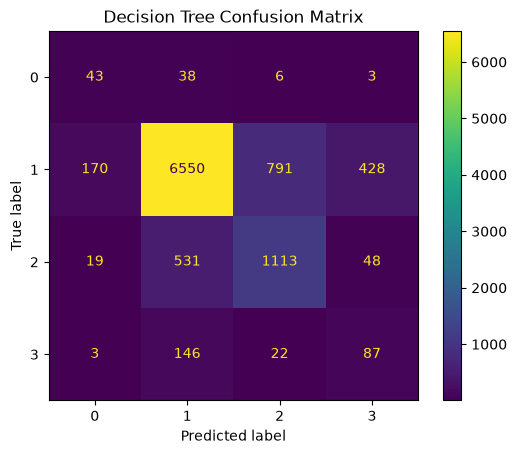

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


cm = confusion_matrix(
    y_test,
    y_test_pred
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.show()

In [14]:
importance = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": final_tree.feature_importances_

})


importance = importance.sort_values(
    by="Importance",
    ascending=False
)


importance.head(20)

,Feature,Importance
2,f5,0.248435
26,f1_Source2,0.078026
4,f15,0.070852
32,f7_freq,0.061965
35,f10_freq,0.058270
0,f3,0.053068
21,f2_month,0.045981
6,f17,0.040202
34,f9_freq,0.037315
36,f12_freq,0.037011


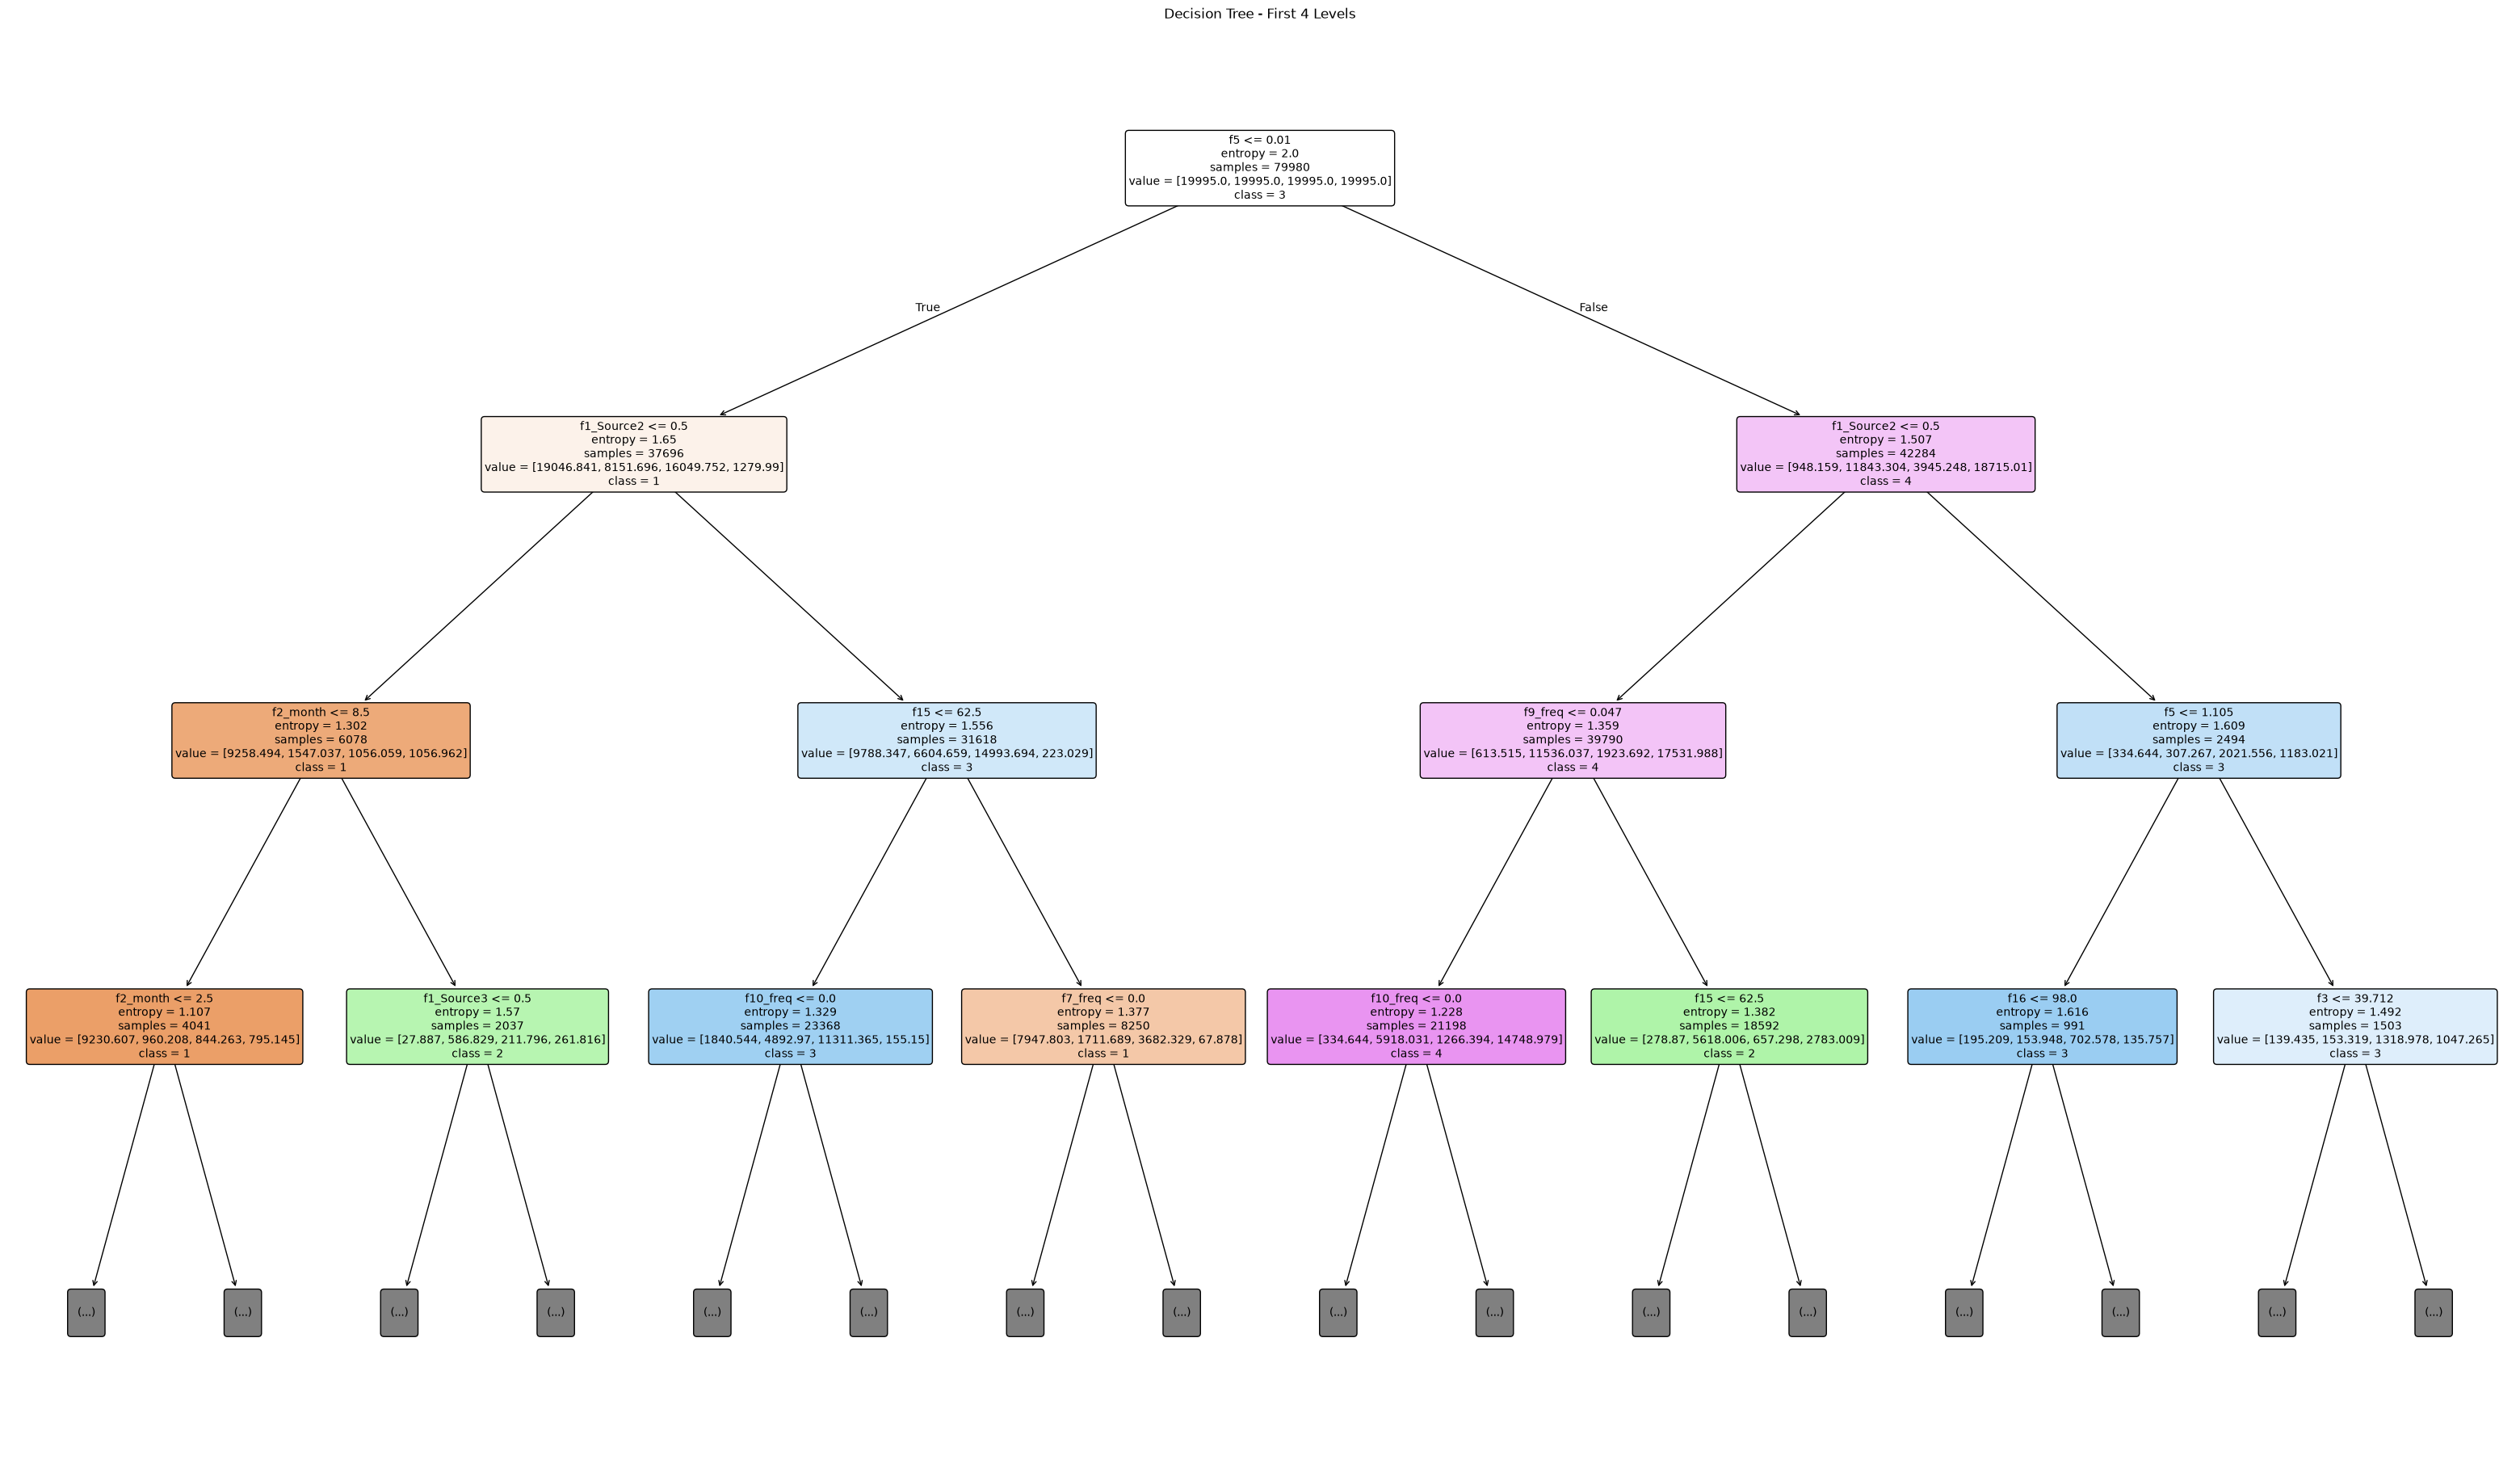

In [15]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import numpy as np

plt.figure(figsize=(40, 23))

plot_tree(
    final_tree,
    feature_names=X_train.columns,
    class_names=[str(c) for c in np.unique(y_train)],
    filled=True,
    rounded=True,
    max_depth=3,   
    fontsize=10
)

plt.title("Decision Tree - First 4 Levels")
plt.show()

## 6.2.2 Random forest

In [16]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from itertools import product

## 6.2.2.1. Hyper parameter tuning of Random Forest

In [17]:
param_grid = {

    "n_estimators": [
        100,
        200
        
    ],

    "max_depth": [
        10,
        20,

        None
    ],

    "min_samples_split": [
        2,
        5
    ],

    "min_samples_leaf": [
        1,
        5
    ],

    "criterion": [
        "gini",
        "entropy"
    ],

    "max_features": [
        "sqrt"
    ]
}

In [18]:
results = []


for n_est, depth, split, leaf, criterion, features in product(
    
    param_grid["n_estimators"],
    param_grid["max_depth"],
    param_grid["min_samples_split"],
    param_grid["min_samples_leaf"],
    param_grid["criterion"],
    param_grid["max_features"]

):

    rf = RandomForestClassifier(

        n_estimators=n_est,
        max_depth=depth,
        min_samples_split=split,
        min_samples_leaf=leaf,
        criterion=criterion,
        max_features=features,

        class_weight="balanced",

        random_state=42,
        n_jobs=-1
    )


    rf.fit(
        X_train,
        y_train
    )


    y_val_pred = rf.predict(
        X_val
    )


    acc = accuracy_score(
        y_val,
        y_val_pred
    )


    macro_f1 = f1_score(
        y_val,
        y_val_pred,
        average="macro"
    )


    results.append({

        "n_estimators": n_est,
        "max_depth": depth,
        "min_samples_split": split,
        "min_samples_leaf": leaf,
        "criterion": criterion,
        "max_features": features,

        "Accuracy": acc,
        "Macro_F1": macro_f1

    })


results_df = pd.DataFrame(results)

## 6.2.2.2 Selected Model

In [19]:
results_df = results_df.sort_values(
    by="Macro_F1",
    ascending=False
)


results_df.head(10)

,n_estimators,max_depth,min_samples_split,min_samples_leaf,criterion,max_features,Accuracy,Macro_F1
23,100,NaN,5,5,entropy,sqrt,0.848054,0.546773
19,100,NaN,2,5,entropy,sqrt,0.848054,0.546773
47,200,NaN,5,5,entropy,sqrt,0.848955,0.542879
43,200,NaN,2,5,entropy,sqrt,0.848955,0.542879
15,100,20.0,5,5,entropy,sqrt,0.837751,0.542502
11,100,20.0,2,5,entropy,sqrt,0.837751,0.542502
35,200,20.0,2,5,entropy,sqrt,0.838752,0.539051
39,200,20.0,5,5,entropy,sqrt,0.838752,0.539051
42,200,NaN,2,5,gini,sqrt,0.848955,0.536444
46,200,NaN,5,5,gini,sqrt,0.848955,0.536444


In [20]:
best = results_df.iloc[0]


final_rf = RandomForestClassifier(

    n_estimators=int(best["n_estimators"]),

    max_depth=(
        None 
        if pd.isna(best["max_depth"])
        else int(best["max_depth"])
    ),

    min_samples_split=int(
        best["min_samples_split"]
    ),

    min_samples_leaf=int(
        best["min_samples_leaf"]
    ),

    criterion=best["criterion"],

    max_features=best["max_features"],

    class_weight="balanced",

    random_state=42,

    n_jobs=-1
)


final_rf.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `met

## 6.2.2.3 Model Analysis

In [21]:
y_test_pred = final_rf.predict(
    X_test
)


print(
    "Test Accuracy:",
    accuracy_score(
        y_test,
        y_test_pred
    )
)


print(
    "Test Macro F1:",
    f1_score(
        y_test,
        y_test_pred,
        average="macro"
    )
)


print(
    classification_report(
        y_test,
        y_test_pred
    )
)

Test Accuracy: 0.8456691338267653
Test Macro F1: 0.5457160633241298
              precision    recall  f1-score   support

           1       0.32      0.34      0.33        90
           2       0.92      0.88      0.90      7939
           3       0.62      0.79      0.70      1711
           4       0.40      0.18      0.25       258

    accuracy                           0.85      9998
   macro avg       0.57      0.55      0.55      9998
weighted avg       0.85      0.85      0.85      9998



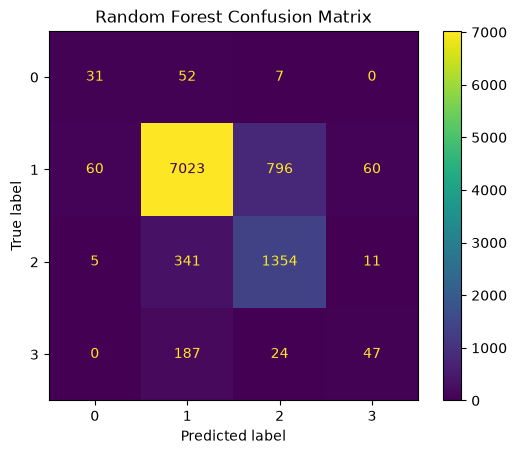

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


cm = confusion_matrix(
    y_test,
    y_test_pred
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

In [23]:
importance_rf = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": final_rf.feature_importances_

})


importance_rf = importance_rf.sort_values(
    by="Importance",
    ascending=False
)


importance_rf.head(20)

,Feature,Importance
2,f5,0.163940
26,f1_Source2,0.083329
1,f4,0.069703
32,f7_freq,0.055471
35,f10_freq,0.055416
21,f2_month,0.055064
4,f15,0.050594
33,f8_freq,0.043227
36,f12_freq,0.042284
0,f3,0.040074


## 6.2.3. XGboost

In [24]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

In [25]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train_enc = encoder.fit_transform(y_train)
y_val_enc = encoder.transform(y_val)
y_test_enc = encoder.transform(y_test)

## 6.2.3.1 Class weighting

In [26]:
# sample_weights = compute_sample_weight(
#     class_weight="balanced",
#     y=y_train_enc
# )

class_weights = {
    1: 5,
    2: 1,
    3: 2,
    4: 4
}
sample_weights = np.array([
    class_weights[y]
    for y in y_train
])

## 6.2.3.2.Hyperparameter Tuning of the XGBoost Model

In [27]:
param_grid = {


"n_estimators":[
    200,
    400,
    600
],


"max_depth":[
    3,
    4,
    5
],


"learning_rate":[
    0.01,
    0.03,
    0.05
],


"min_child_weight":[
    3,
    5
],


"subsample":[
    0.8
],


"colsample_bytree":[
    0.8
]

}

In [28]:
from itertools import product


results=[]


for n_est, depth, lr, child in product(

    param_grid["n_estimators"],

    param_grid["max_depth"],

    param_grid["learning_rate"],

    param_grid["min_child_weight"]

):


    model = XGBClassifier(

        n_estimators=n_est,

        max_depth=depth,

        learning_rate=lr,

        min_child_weight=child,


        subsample=0.8,

        colsample_bytree=0.8,


        gamma=0.1,


        objective="multi:softmax",

        num_class=4,


        eval_metric="mlogloss",


        random_state=42,

        n_jobs=-1

    )


    model.fit(

        X_train,

        y_train_enc,

        sample_weight=sample_weights

    )


    val_pred = model.predict(
        X_val
    )


    macro_f1 = f1_score(

        y_val_enc,

        val_pred,

        average="macro"

    )


    acc = accuracy_score(

        y_val_enc,

        val_pred

    )


    results.append({

        "n_estimators":n_est,

        "max_depth":depth,

        "learning_rate":lr,

        "min_child_weight":child,

        "Accuracy":acc,

        "Macro_F1":macro_f1

    })



results_df = pd.DataFrame(results)

In [29]:
results_df = results_df.sort_values(
    by="Macro_F1",
    ascending=False
)


results_df.head(10)

,n_estimators,max_depth,learning_rate,min_child_weight,Accuracy,Macro_F1
52,600,5,0.05,3,0.861759,0.561975
53,600,5,0.05,5,0.861258,0.558859
34,400,5,0.05,3,0.858157,0.557846
17,200,5,0.05,5,0.850755,0.553189
35,400,5,0.05,5,0.858758,0.552523
16,200,5,0.05,3,0.851355,0.552246
44,600,4,0.03,3,0.850555,0.550440
51,600,5,0.03,5,0.856257,0.549594
28,400,4,0.05,3,0.851655,0.548441
50,600,5,0.03,3,0.855857,0.547756


## 6.2.3.3. Selected Model

In [30]:
best = results_df.iloc[0]


final_xgb = XGBClassifier(

    n_estimators=int(
        best["n_estimators"]
    ),

    max_depth=int(
        best["max_depth"]
    ),

    learning_rate=
        best["learning_rate"],


    min_child_weight=
        best["min_child_weight"],


    subsample=0.8,

    colsample_bytree=0.8,

    gamma=0.1,


    objective="multi:softmax",

    num_class=4,


    eval_metric="mlogloss",


    random_state=42,

    n_jobs=-1

)


final_xgb.fit(

    X_train,

    y_train_enc,

    sample_weight=sample_weights

)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fro

## 6.2.3.4. Model Analysis

In [31]:
y_test_pred_enc = final_xgb.predict(
    X_test
)


y_test_pred = encoder.inverse_transform(
    y_test_pred_enc
)


print(
    "Test Accuracy:",
    accuracy_score(
        y_test,
        y_test_pred
    )
)


print(
    "Test Macro F1:",
    f1_score(
        y_test,
        y_test_pred,
        average="macro"
    )
)


print(
    classification_report(
        y_test,
        y_test_pred
    )
)

Test Accuracy: 0.864872974594919
Test Macro F1: 0.5768204940462925
              precision    recall  f1-score   support

           1       0.35      0.30      0.32        90
           2       0.93      0.90      0.92      7939
           3       0.68      0.81      0.74      1711
           4       0.36      0.31      0.33       258

    accuracy                           0.86      9998
   macro avg       0.58      0.58      0.58      9998
weighted avg       0.87      0.86      0.87      9998



In [32]:
importance_xgb = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": final_xgb.feature_importances_

})


importance_xgb = importance_xgb.sort_values(
    by="Importance",
    ascending=False
)


importance_xgb.head(20)

,Feature,Importance
26,f1_Source2,0.261671
18,f31,0.081808
2,f5,0.052592
35,f10_freq,0.044929
32,f7_freq,0.044182
10,f23,0.039910
27,f1_Source3,0.036606
21,f2_month,0.035077
1,f4,0.027352
34,f9_freq,0.026034


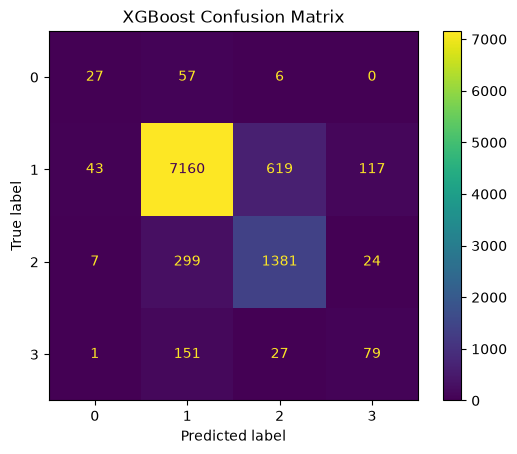

In [33]:
cm = confusion_matrix(
    y_test,
    y_test_pred
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.title(
    "XGBoost Confusion Matrix"
)

plt.show()